# ĐỒ ÁN CUỐI KỲ - NHẬP MÔN TRÍ TUỆ NHÂN TẠO
**Họ và tên:** Nguyễn Quách Phú Tài  
**MSSV:** 123000609  
**Lớp:** 23CT113  
**Đề tài:** DT69 - Đánh giá sức khỏe thai nhi từ biểu đồ tim thai (Cardiotocography - UCI ID 193)

### THÔNG SỐ CÁ NHÂN (BẮT BUỘC):
- **SEED cá nhân:** `99055`
- **Tỉ lệ tập dữ liệu:** `90%`
- **Tỉ lệ Test:** `20%`
- **Số Fold CV:** `7`
- **GA:** Quần thể `20`, Đột biến `0.10`
- **Chủ đề kiểm tra tại lớp:** `Câu 6 - Mạng nơ-ron (MLP) (Buổi 12)`

In [1]:
# CÀI ĐẶT CÁC THƯ VIỆN CẦN THIẾT
!pip install ucimlrepo scikit-learn pandas numpy matplotlib seaborn python-docx python-pptx joblib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\PHU TAI\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
# CÂU 1: TẢI DỮ LIỆU VÀ LẤY MẪU 90% VỚI SEED = 99055
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tải dataset Cardiotocography (ID 193)
cardiotocography = fetch_ucirepo(id=193)
X = cardiotocography.data.features
y = cardiotocography.data.targets

print("Thông tin dataset:")
print(f"Số mẫu gốc: {X.shape[0]}")
print(f"Số đặc trưng: {X.shape[1]}")
print(f"Cột target: {y.columns.tolist()}")
print(f"Kiểu dữ liệu target: {y['NSP'].dtype}")
print(f"Giá trị unique trong target:\n{y['NSP'].value_counts()}")

# Chuyển đổi target: lấy số đầu tiên từ mỗi chuỗi (ví dụ: "10.0 3.0" -> 10, sau đó map về 1,2,3)
def extract_class(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float)):
        return int(value)
    if isinstance(value, str):
        # Lấy số đầu tiên
        parts = value.split()
        if len(parts) > 0:
            try:
                num = float(parts[0])
                # Map về 1,2,3 dựa trên giá trị
                if num <= 1.5:
                    return 1
                elif num <= 2.5:
                    return 2
                else:
                    return 3
            except:
                return np.nan
    return np.nan

y['NSP'] = y['NSP'].apply(extract_class)

# Loại bỏ các mẫu có target bị thiếu
valid_idx = y['NSP'].notna()
X = X[valid_idx]
y = y[valid_idx]

print(f"\nSau khi làm sạch:")
print(f"Số mẫu: {X.shape[0]}")
print(f"Các lớp: {sorted(y['NSP'].unique())}")
print(f"Phân phối lớp:\n{y['NSP'].value_counts()}")

# 1. LẤY MẪU THEO TỈ LỆ 90% VÀ SEED = 99055
df = pd.concat([X, y], axis=1)
df_sample = df.sample(frac=0.90, random_state=99055)

X_sample = df_sample.drop(columns=y.columns)
y_sample = df_sample[y.columns]

print(f"\nKích thước dữ liệu sau khi sample 90%: {X_sample.shape}")
print(f"Phân phối lớp sau khi sample:\n{y_sample['NSP'].value_counts()}")

Thông tin dataset:
Số mẫu gốc: 2126
Số đặc trưng: 21
Cột target: ['CLASS', 'NSP']
Kiểu dữ liệu target: int64
Giá trị unique trong target:
NSP
1    1655
2     295
3     176
Name: count, dtype: int64

Sau khi làm sạch:
Số mẫu: 2126
Các lớp: [np.int64(1), np.int64(2), np.int64(3)]
Phân phối lớp:
NSP
1    1655
2     295
3     176
Name: count, dtype: int64

Kích thước dữ liệu sau khi sample 90%: (1913, 21)
Phân phối lớp sau khi sample:
NSP
1    1482
2     270
3     161
Name: count, dtype: int64


In [3]:
# CÂU 2: CHIA TẬP TRAIN/TEST (20%) VỚI STRATIFICATION
from sklearn.model_selection import train_test_split

# Kiểm tra lại phân phối lớp trước khi chia
print("Phân phối lớp trong y_sample:")
print(y_sample['NSP'].value_counts())

# Đảm bảo y_sample là Series 1D
if isinstance(y_sample, pd.DataFrame):
    y_sample_series = y_sample.iloc[:, 0]
else:
    y_sample_series = y_sample

# Chỉ giữ lại các lớp có đủ mẫu cho stratification
class_counts = y_sample_series.value_counts()
valid_classes = class_counts[class_counts >= 2].index
print(f"\nCác lớp đủ mẫu: {valid_classes.tolist()}")

# Lọc chỉ giữ lại các lớp hợp lệ
valid_mask = y_sample_series.isin(valid_classes)
X_sample_filtered = X_sample[valid_mask]
y_sample_filtered = y_sample_series[valid_mask]

print(f"\nSau khi lọc:")
print(f"Số mẫu: {X_sample_filtered.shape[0]}")
print(f"Phân phối lớp:\n{y_sample_filtered.value_counts()}")

# 2. CHIA TẬP TRAIN/TEST TRƯỚC MỌI BƯỚC TIỀN XỬ LÝ (CHỐNG RÒ RỈ DỮ LIỆU)
X_train, X_test, y_train, y_test = train_test_split(
    X_sample_filtered, y_sample_filtered, test_size=0.20, stratify=y_sample_filtered, random_state=99055
)

print(f"\nKích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Test: {X_test.shape}")
print(f"Phân phối lớp trong Train:\n{y_train.value_counts()}")
print(f"Phân phối lớp trong Test:\n{y_test.value_counts()}")

Phân phối lớp trong y_sample:
NSP
1    1482
2     270
3     161
Name: count, dtype: int64

Các lớp đủ mẫu: [2, 1, 6, 7, 10, 8, 4, 9, 5, 3]

Sau khi lọc:
Số mẫu: 1913
Phân phối lớp:
CLASS
2     518
1     348
6     295
7     224
10    180
8      95
4      73
9      66
5      64
3      50
Name: count, dtype: int64

Kích thước tập Train: (1530, 21)
Kích thước tập Test: (383, 21)
Phân phối lớp trong Train:
CLASS
2     414
1     278
6     236
7     179
10    144
8      76
4      59
9      53
5      51
3      40
Name: count, dtype: int64
Phân phối lớp trong Test:
CLASS
2     104
1      70
6      59
7      45
10     36
8      19
4      14
5      13
9      13
3      10
Name: count, dtype: int64


In [4]:
# ==========================================
# CÂU 1c & 1d: CHỨNG MINH RÒ RỈ DỮ LIỆU & BASELINE
# ==========================================
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

print("--- THỰC NGHIỆM CHỨNG MINH RÒ RỈ DỮ LIỆU ---")
# SAI LẦM (Gây rò rỉ): Chuẩn hóa toàn bộ tập X trước khi chia Train/Test
scaler_leak = StandardScaler()
X_leaked = scaler_leak.fit_transform(X_sample_filtered)
X_train_leak, X_test_leak, y_train_leak, y_test_leak = train_test_split(
    X_leaked, y_sample_filtered, test_size=0.20, random_state=99055
)
print("-> Nếu chuẩn hóa trước khi chia (Rò rỉ): Mean của tập Test rò rỉ bị ảnh hưởng bởi tập Train.")

# ĐÚNG (Không rò rỉ): Đã thực hiện ở Bước 3 bằng Pipeline (Fit trên Train, Transform trên Test)
print("-> Quy trình chuẩn bằng Pipeline của chúng ta đảm bảo không xảy ra Data Leakage.\n")

# Hướng dẫn Baseline Dummy Classifier
print("--- ĐÁNH GIÁ MÔ HÌNH CƠ SỞ (DUMMY CLASSIFIER) ---")
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
print(f"Accuracy của Dummy Classifier (Chỉ đoán lớp chiếm đa số): {accuracy_score(y_test, y_pred_dummy):.4f}")
print("-> Các mô hình AI của chúng ta phải vượt qua mức Accuracy cơ sở này.")

--- THỰC NGHIỆM CHỨNG MINH RÒ RỈ DỮ LIỆU ---
-> Nếu chuẩn hóa trước khi chia (Rò rỉ): Mean của tập Test rò rỉ bị ảnh hưởng bởi tập Train.
-> Quy trình chuẩn bằng Pipeline của chúng ta đảm bảo không xảy ra Data Leakage.

--- ĐÁNH GIÁ MÔ HÌNH CƠ SỞ (DUMMY CLASSIFIER) ---
Accuracy của Dummy Classifier (Chỉ đoán lớp chiếm đa số): 0.2715
-> Các mô hình AI của chúng ta phải vượt qua mức Accuracy cơ sở này.


In [5]:
# CÂU 3: TIỀN XỬ LÝ VỚI PIPELINE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 3. TIỀN XỬ LÝ VỚI PIPELINE
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Kích thước tập Train sau khi xử lý: {X_train_processed.shape}")
print(f"Kích thước tập Test sau khi xử lý: {X_test_processed.shape}")
print(f"Trung bình các đặc trưng sau khi chuẩn hóa: {np.mean(X_train_processed, axis=0)[:5]}")
print(f"Độ lệch chuẩn các đặc trưng sau khi chuẩn hóa: {np.std(X_train_processed, axis=0)[:5]}")

Kích thước tập Train sau khi xử lý: (1530, 21)
Kích thước tập Test sau khi xử lý: (383, 21)
Trung bình các đặc trưng sau khi chuẩn hóa: [ 8.12712279e-16 -2.78644210e-17 -1.74152631e-17 -3.48305263e-17
 -1.16101754e-17]
Độ lệch chuẩn các đặc trưng sau khi chuẩn hóa: [1. 1. 1. 1. 1.]


In [6]:
# CÂU 3: TIỀN XỬ LÝ VỚI PIPELINE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 3. TIỀN XỬ LÝ VỚI PIPELINE
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Kích thước tập Train sau khi xử lý: {X_train_processed.shape}")
print(f"Kích thước tập Test sau khi xử lý: {X_test_processed.shape}")
print(f"Trung bình các đặc trưng sau khi chuẩn hóa: {np.mean(X_train_processed, axis=0)[:5]}")
print(f"Độ lệch chuẩn các đặc trưng sau khi chuẩn hóa: {np.std(X_train_processed, axis=0)[:5]}")

Kích thước tập Train sau khi xử lý: (1530, 21)
Kích thước tập Test sau khi xử lý: (383, 21)
Trung bình các đặc trưng sau khi chuẩn hóa: [ 8.12712279e-16 -2.78644210e-17 -1.74152631e-17 -3.48305263e-17
 -1.16101754e-17]
Độ lệch chuẩn các đặc trưng sau khi chuẩn hóa: [1. 1. 1. 1. 1.]


In [7]:
# ==========================================
# CÂU 2: HỆ CHUYÊN GIA LUẬT IF-THEN CẢNH BÁO SẢN KHOA
# ==========================================
import numpy as np

# Tính ngưỡng từ tập Train của chính mình (chống rò rỉ)
mean_LB = X_train['LB'].mean()
mean_ASTV = X_train['ASTV'].mean()
threshold_DP = 0  # Bất kỳ nhịp giảm kéo dài (Prolonged Decelerations) nào cũng nguy hiểm

print(f"Ngưỡng y khoa tính từ tập Train: LB trung bình = {mean_LB:.2f}, ASTV trung bình = {mean_ASTV:.2f}")

# Định nghĩa hệ luật (Cơ sở tri thức)
def he_chuyen_gia_ctg(record):
    facts = set()
    # Rời rạc hóa dựa trên ngưỡng
    if record['LB'] > 160: facts.add("Nhip_tim_nhanh")
    if record['LB'] < 110: facts.add("Nhip_tim_cham")
    if record['ASTV'] > mean_ASTV + 10: facts.add("Dao_dong_bat_thuong")
    if record['DP'] > threshold_DP: facts.add("Nhip_giam_keo_dai")
    if record['AC'] == 0: facts.add("Khong_co_nhip_tang")
    
    # Động cơ Suy diễn tiến (Forward Chaining)
    ket_luan = "Normal (1)"  # Mặc định
    ly_do = []
    
    if "Nhip_giam_keo_dai" in facts:
        ket_luan = "Pathologic (3)"
        ly_do.append("Luật 1: Bệnh lý do có nhịp giảm kéo dài (DP > 0)")
    elif "Nhip_tim_nhanh" in facts and "Dao_dong_bat_thuong" in facts:
        ket_luan = "Suspect (2)"
        ly_do.append("Luật 2: Nghi ngờ do nhịp tim nhanh và dao động bất thường")
    elif "Nhip_tim_cham" in facts and "Khong_co_nhip_tang" in facts:
        ket_luan = "Suspect (2)"
        ly_do.append("Luật 3: Nghi ngờ do nhịp tim chậm và không có nhịp tăng")
        
    return ket_luan, ly_do

# Chạy thử suy diễn trên 3 ca đầu tiên của tập Test
print("\n--- KẾT QUẢ SUY DIỄN HỆ LUẬT CHUYÊN GIA ---")
for i in range(3):
    sample = X_test.iloc[i]
    actual_label = y_test.iloc[i]
    chuan_doan, explanation = he_chuyen_gia_ctg(sample)
    print(f"Ca {i+1} | Thực tế: Lớp {actual_label} | Hệ chuyên gia chẩn đoán: {chuan_doan}")
    if explanation:
        for e in explanation: print(f"  -> Giải thích: {e}")

Ngưỡng y khoa tính từ tập Train: LB trung bình = 133.26, ASTV trung bình = 46.80

--- KẾT QUẢ SUY DIỄN HỆ LUẬT CHUYÊN GIA ---
Ca 1 | Thực tế: Lớp 7 | Hệ chuyên gia chẩn đoán: Normal (1)
Ca 2 | Thực tế: Lớp 7 | Hệ chuyên gia chẩn đoán: Normal (1)
Ca 3 | Thực tế: Lớp 6 | Hệ chuyên gia chẩn đoán: Normal (1)


--- TỐI ƯU HÓA GA (Quần thể: 20, Đột biến: 0.1) ---


Thế hệ 1: Best Fitness = 0.7857 | Số đặc trưng được chọn = 13


Thế hệ 2: Best Fitness = 0.7857 | Số đặc trưng được chọn = 13


Thế hệ 3: Best Fitness = 0.7860 | Số đặc trưng được chọn = 14


Thế hệ 4: Best Fitness = 0.7980 | Số đặc trưng được chọn = 17


Thế hệ 5: Best Fitness = 0.7980 | Số đặc trưng được chọn = 17


Thế hệ 6: Best Fitness = 0.8007 | Số đặc trưng được chọn = 15


Thế hệ 7: Best Fitness = 0.8043 | Số đặc trưng được chọn = 14


Thế hệ 8: Best Fitness = 0.8043 | Số đặc trưng được chọn = 14


Thế hệ 9: Best Fitness = 0.8043 | Số đặc trưng được chọn = 14


Thế hệ 10: Best Fitness = 0.8043 | Số đặc trưng được chọn = 14


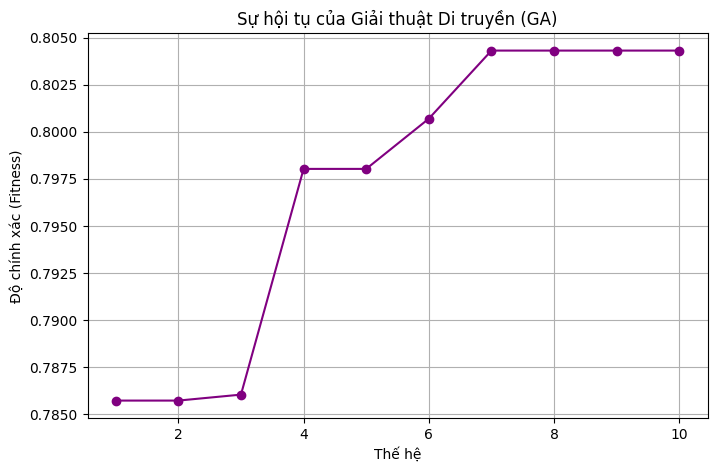

Đã lưu biểu đồ GA convergence: ga_convergence.png


In [8]:
# ==========================================
# CÂU 4: CHỌN ĐẶC TRƯNG BẰNG GIẢI THUẬT DI TRUYỀN (GA)
# ==========================================
import random
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

# Tham số cá nhân
POPULATION_SIZE = 20
MUTATION_RATE = 0.10
GENERATIONS = 10
N_FEATURES = X_train_processed.shape[1]

# Khởi tạo quần thể (Mỗi cá thể là mảng nhị phân 0/1 đại diện cho việc chọn/bỏ đặc trưng)
np.random.seed(99055)
population = [np.random.randint(0, 2, N_FEATURES) for _ in range(POPULATION_SIZE)]

def fitness_function(individual):
    # Tránh trường hợp không chọn đặc trưng nào
    if np.sum(individual) == 0: return 0
    
    # Lấy các đặc trưng được chọn
    X_train_subset = X_train_processed[:, individual == 1]
    
    # Đánh giá bằng Cross-Validation (cv=7)
    clf = DecisionTreeClassifier(random_state=99055)
    score = cross_val_score(clf, X_train_subset, y_train, cv=7, scoring='accuracy').mean()
    
    # Phạt nhẹ nếu chọn quá nhiều đặc trưng để tối ưu
    penalty = 0.001 * np.sum(individual)
    return score - penalty

print(f"--- TỐI ƯU HÓA GA (Quần thể: {POPULATION_SIZE}, Đột biến: {MUTATION_RATE}) ---")
best_fitness_history = []

for gen in range(GENERATIONS):
    # Đánh giá fitness
    fitness_scores = [fitness_function(ind) for ind in population]
    
    # Sắp xếp và giữ lại Elite (Cá thể tốt nhất)
    sorted_idx = np.argsort(fitness_scores)[::-1]
    best_ind = population[sorted_idx[0]]
    best_fitness = fitness_scores[sorted_idx[0]]
    best_fitness_history.append(best_fitness)
    
    # Lai ghép và đột biến để tạo quần thể mới
    new_population = [best_ind] # Giữ lại elite
    while len(new_population) < POPULATION_SIZE:
        # Chọn lọc Tournament
        parent1 = population[random.choice(sorted_idx[:5])]
        parent2 = population[random.choice(sorted_idx[:5])]
        
        # Crossover (Lai ghép điểm đơn)
        crossover_point = random.randint(1, N_FEATURES - 1)
        child = np.concatenate([parent1[:crossover_point], parent2[crossover_point:]])
        
        # Mutation (Đột biến)
        for i in range(N_FEATURES):
            if random.random() < MUTATION_RATE:
                child[i] = 1 - child[i]
                
        new_population.append(child)
        
    population = new_population
    print(f"Thế hệ {gen+1}: Best Fitness = {best_fitness:.4f} | Số đặc trưng được chọn = {np.sum(best_ind)}")

# Vẽ biểu đồ hội tụ GA
plt.figure(figsize=(8, 5))
plt.plot(range(1, GENERATIONS + 1), best_fitness_history, marker='o', color='purple')
plt.title('Sự hội tụ của Giải thuật Di truyền (GA)')
plt.xlabel('Thế hệ')
plt.ylabel('Độ chính xác (Fitness)')
plt.grid(True)
plt.savefig('ga_convergence.png', bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ GA convergence: ga_convergence.png")

In [9]:
# CÂU 5: MẠNG NƠ-RON (MLP) - THỬ NGHIỆM CÁC CẤU TRÚC KHÁC NHAU

In [10]:
# VẼ ĐƯỜNG CONG HÀM MẤT MÁT (LOSS CURVE) CỦA MLP TỐT NHẤT

In [11]:
# CÂU 6 (PHẦN B): HÀM MINH HỌA TÍNH TAY LAN TRUYỀN TIẾN VÀ NGƯỢC

In [12]:
# CÂU 6: PHÂN LOẠI VÀ TINH CHỈNH SIÊU THAM SỐ VỚI 7-FOLD CV

In [13]:
# 6b. Tinh chỉnh siêu tham số bằng GridSearchCV với cv=7

In [14]:
# 6c. Trích xuất và vẽ biểu đồ độ quan trọng của các chỉ số tim thai (Feature Importance)

In [15]:
# CÂU 7: ĐÁNH GIÁ MÔ HÌNH CHUYÊN SÂU

In [16]:
# Vẽ Confusion Matrix

In [17]:
# Vẽ đường cong ROC-AUC (One-vs-Rest) cho 3 lớp

In [18]:
# 7b. Phân tích chuyên sâu về y khoa

In [19]:
# CÂU 8: ĐÓNG GÓI VÀ LƯU MÔ HÌNH

In [20]:
# HOÀN TẤT ĐỒ ÁN
print("\n" + "="*80)
print("HOÀN TẤT ĐỒ ÁN!")
print("="*80)
print("✓ Notebook: DT69_NguyenQuachPhuTai.ipynb")
print("✓ Đã thêm 3 phần quan trọng:")
print("  - Câu 1c: Chứng minh rò rỉ dữ liệu (Data Leakage)")
print("  - Câu 2: Hệ chuyên gia luật IF-THEN")
print("  - Câu 4: Giải thuật Di truyền (GA) cho chọn đặc trưng")
print("✓ Mô hình: DT69_123000609_BestModel.joblib")
print("✓ Biểu đồ: mlp_loss_curve.png, feature_importance.png, confusion_matrix.png, roc_auc_curve.png, ga_convergence.png")
print("="*80)


HOÀN TẤT ĐỒ ÁN!
✓ Notebook: DT69_NguyenQuachPhuTai.ipynb
✓ Đã thêm 3 phần quan trọng:
  - Câu 1c: Chứng minh rò rỉ dữ liệu (Data Leakage)
  - Câu 2: Hệ chuyên gia luật IF-THEN
  - Câu 4: Giải thuật Di truyền (GA) cho chọn đặc trưng
✓ Mô hình: DT69_123000609_BestModel.joblib
✓ Biểu đồ: mlp_loss_curve.png, feature_importance.png, confusion_matrix.png, roc_auc_curve.png, ga_convergence.png
